In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skimage.io as skio
from skimage.color import rgb2gray

from harris import get_harris_corners, dist2  

N_POINTS = 500   
RATIO = 0.9   

def ANMS(im, n_points = N_POINTS, ratio = RATIO):
    h, corners = get_harris_corners(im)   # corners: (2, n)
    strength = h[corners[0], corners[1]]
    corners = corners[:, np.argsort(-strength)[:3000]]
    h, corners = np.asarray(h, dtype=float), np.asarray(corners, dtype=int)

    n = corners.shape[1]
    c, r = h.shape[0], h.shape[1]

    dist = dist2(corners.T, corners.T)

    mask = np.zeros((n, n))
    f = h[corners[0], corners[1]] 
    mask = f[:, None] < ratio * f[None, :] 
    
    rs = np.full(n, np.inf)

    rs = np.where(mask, dist, np.inf).min(axis=1)

    order = np.argsort(-rs)                   
    return corners[:, order[:n_points]]



In [2]:
import os
import glob
import numpy as np
import skimage.io as skio
from skimage.color import rgb2gray
from skimage.transform import rescale
from PIL import Image, ImageOps

IMG_DIR = os.path.join("..", "proj4a", "images")

def load_image(name, scale=0.25):
    """Load an image from proj4a/images. Returns (color, gray), both float in [0, 1]."""
    # PIL + exif_transpose applies the phone's rotation tag (skio.imread ignores it)
    im = np.asarray(ImageOps.exif_transpose(Image.open(os.path.join(IMG_DIR, name))).convert("RGB"))
    im = rescale(im, scale, channel_axis=-1, anti_aliasing=True) if scale != 1 else im / 255.0
    gray = rgb2gray(im)
    return im, gray

im_color, im_gray = load_image("morocco1.jpg") 
print(im_color.shape, im_gray.shape)

(1008, 756, 3) (1008, 756)


In [3]:
_, hc = get_harris_corners(im_gray)
print(hc.shape)

(2, 20189)


In [4]:
anms = ANMS(im_gray)

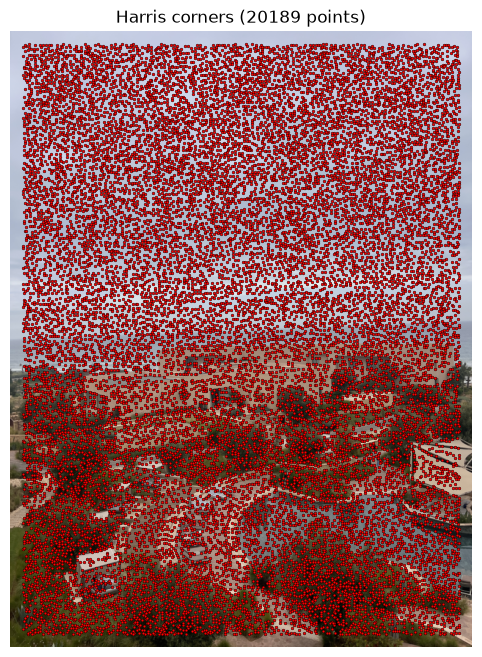

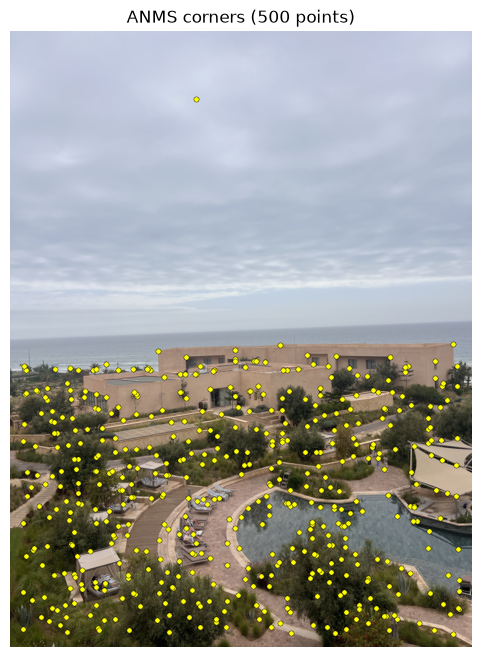

In [5]:
import os
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

def plot_points(im, pts, title, save_path, color="red", size=6):
    """pts: (2, N) array of (row, col)."""
    plt.figure(figsize=(10, 8))
    plt.imshow(im, cmap="gray")
    plt.scatter(pts[1], pts[0], s=size, c=color, edgecolors="black", linewidths=0.3)
    plt.title(f"{title} ({pts.shape[1]} points)")
    plt.axis("off")
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

# Figure 1: all Harris corners
plot_points(im_color, hc, "Harris corners", "results/harris_corners.png",
            color="red", size=4)

# Figure 2: corners after ANMS
plot_points(im_color, anms, "ANMS corners", "results/anms_corners.png",
            color="yellow", size=14)

In [6]:
anms.shape

(2, 500)

In [7]:
from scipy.ndimage import gaussian_filter

def feature_extraction(im, anms):
    anms = anms.T
    features = []
    blurred = gaussian_filter(im, sigma=2)      

    for coord in anms:
        x, y = coord
        window = blurred[x - 20: x + 20, y - 20: y + 20]
        
        patch = window[2::5, 2::5] 
        patch = (patch - patch.mean()) / (patch.std() + 1e-8)

        features.append(patch)

    return np.array(features)

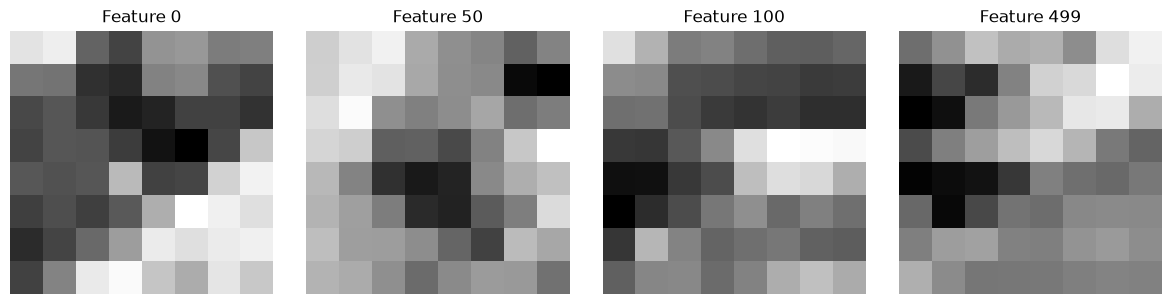

In [8]:
features = feature_extraction(im_gray, anms)

idxs = [0, 50, 100, -1]

fig, axes = plt.subplots(1, len(idxs), figsize=(3 * len(idxs), 3))
for ax, i in zip(axes, idxs):
    ax.imshow(features[i].reshape(8, 8), cmap="gray", interpolation="nearest")
    ax.set_title(f"Feature {i if i >= 0 else len(features) + i}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [9]:
anms = ANMS(im_gray)

In [10]:
im_color2, im_gray2 = load_image("morocco2.jpg")
anms2 = ANMS(im_gray2)
features2 = feature_extraction(im_gray2, anms2)

In [11]:
anms, anms2 = anms.T, anms2.T
features, features2 = features.reshape(features.shape[0], -1), features2.reshape(features2.shape[0], -1)

print(anms.shape, anms2.shape, features.shape, features2.shape)

(500, 2) (500, 2) (500, 64) (500, 64)


In [12]:
d_matrix = dist2(features, features2)

closest_2 = np.argsort(d_matrix, axis=1)[:, :2]
closest_2.shape

(500, 2)

In [13]:
thresholds = [0.3, 0.5, 0.7]

rows = np.arange(len(d_matrix))
e1 = d_matrix[rows, closest_2[:, 0]]     
e2 = d_matrix[rows, closest_2[:, 1]]      
er = np.sqrt(e1) / np.sqrt(e2 + 1e-12)        

matches = {}
for t in thresholds:
    keep = er < t
    i_idx = np.where(keep)[0]       
    j_idx = closest_2[keep, 0]           
    matches[t] = np.stack([i_idx, j_idx], axis=1)  
    print(f"threshold {t}: {len(i_idx)} matches")

threshold 0.3: 20 matches
threshold 0.5: 70 matches
threshold 0.7: 117 matches


In [14]:
pairs = matches[0.5]
pts1 = anms[pairs[:, 0]].T 
pts2 = anms2[pairs[:, 1]]  .T 

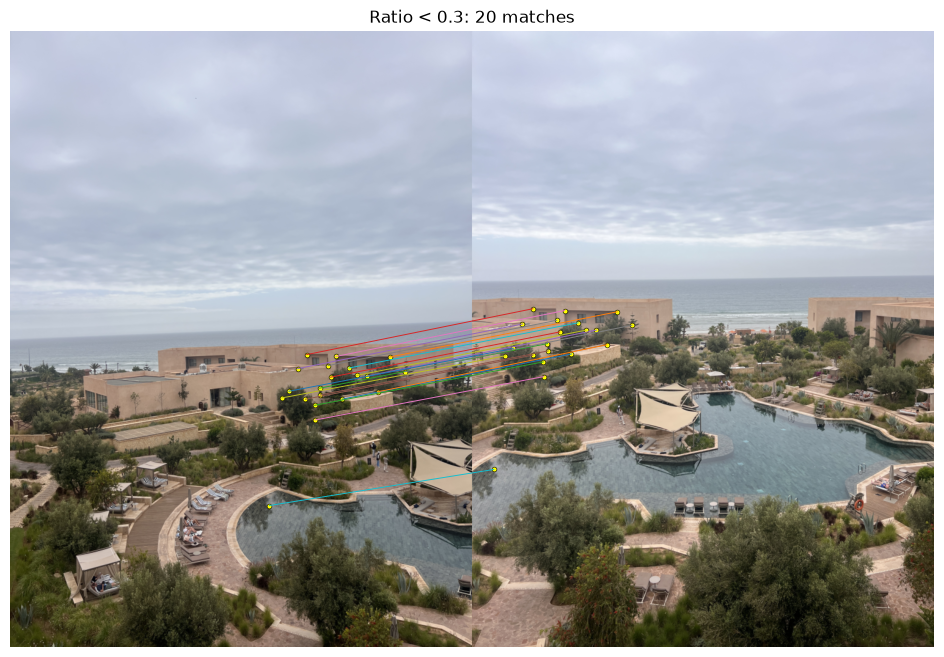

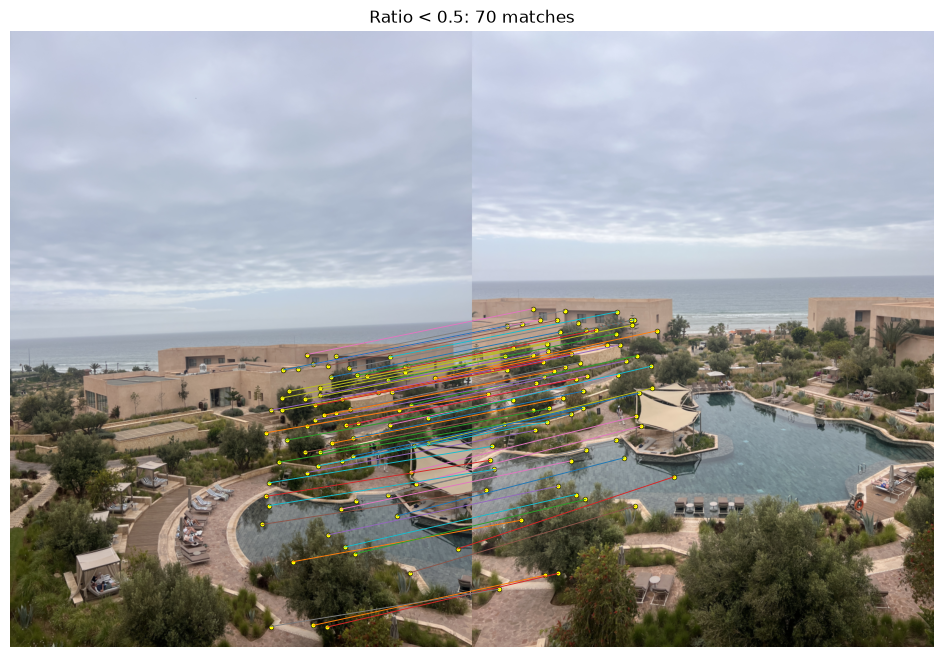

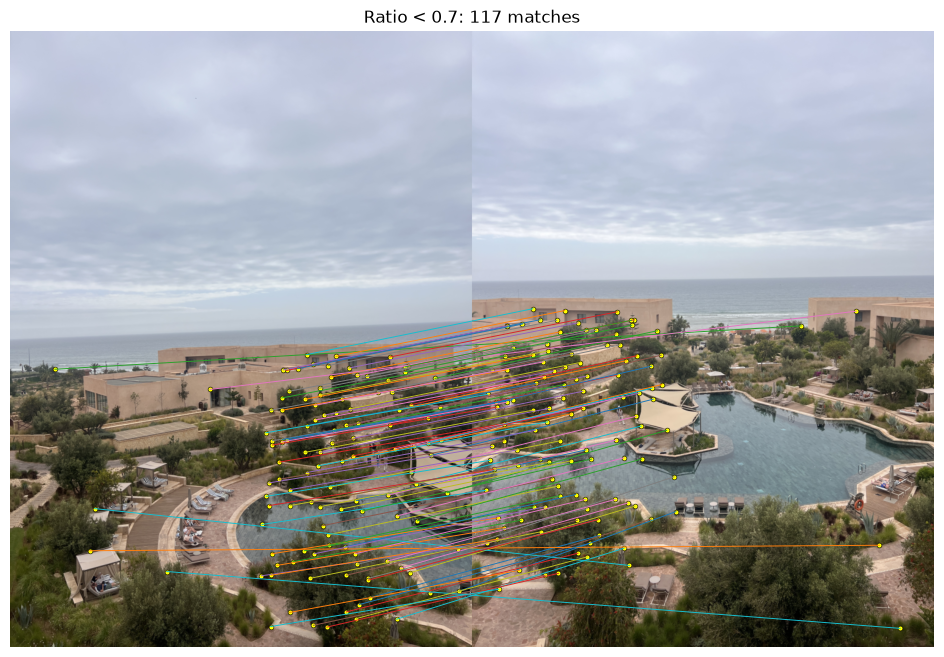

In [15]:
def show_matches(im1, im2, pts1, pts2, title="", save_path=None):
    h = max(im1.shape[0], im2.shape[0])
    canvas = np.zeros((h, im1.shape[1] + im2.shape[1], 3))
    canvas[:im1.shape[0], :im1.shape[1]] = im1
    canvas[:im2.shape[0], im1.shape[1]:] = im2
    off = im1.shape[1]

    plt.figure(figsize=(16, 8))
    plt.imshow(canvas)
    for (r1, c1), (r2, c2) in zip(pts1.T, pts2.T):
        plt.plot([c1, c2 + off], [r1, r2], "-", lw=0.7)
        plt.scatter([c1, c2 + off], [r1, r2], s=12, c="yellow", edgecolors="black", linewidths=0.4)
    plt.title(title)
    plt.axis("off")
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

for t in thresholds:
    pairs = matches[t]
    show_matches(im_color, im_color2,
                 anms[pairs[:, 0]].T, anms2[pairs[:, 1]].T,
                 title=f"Ratio < {t}: {len(pairs)} matches")

In [16]:
import numpy as np

# code from part A
import numpy as np


# code from ProjA, now with a scale input
def computeH(im1_pts, im2_pts, scale=1.0):
    im1_pts = np.asarray(im1_pts, dtype=float) * scale
    im2_pts = np.asarray(im2_pts, dtype=float) * scale

    A, b = [], []
    for (x1, y1), (x2, y2) in zip(im1_pts, im2_pts):
        A.append([x1, y1, 1, 0, 0, 0, -x1 * x2, -y1 * x2])
        A.append([0, 0, 0, x1, y1, 1, -x1 * y2, -y1 * y2])
        b.extend([x2, y2])
    A, b = np.array(A), np.array(b)

    h = np.linalg.lstsq(A, b, rcond=None)[0]
    err = np.sum((A @ h - b) ** 2)
    return np.append(h, 1).reshape(3, 3), err

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.util import img_as_float

def feather_weights(im):
    h, w = im.shape[:2]
    y, x = np.indices((h, w))

    weights = np.minimum.reduce([
        x + 1, w - x,
        y + 1, h - y
    ]).astype(float)

    return weights / weights.max()


def make_mosaic(im1, im2, H):
    im1 = img_as_float(im1)
    im2 = img_as_float(im2)

    h1, w1 = im1.shape[:2]
    h2, w2 = im2.shape[:2]

    corners = H @ np.array([[0, 0, 1], [w1-1, 0, 1], [0, h1-1, 1], [w1-1, h1-1, 1]]).T
    corners = corners[:2] / corners[2]
    xmin = max(min(0, np.floor(corners[0].min())), -(w2 // 2))
    ymin = max(min(0, np.floor(corners[1].min())), -(h2 // 2))
    xmax = min(max(w2 - 1, np.ceil(corners[0].max())), w2 - 1 + w2 // 2)
    ymax = min(max(h2 - 1, np.ceil(corners[1].max())), h2 - 1 + h2 // 2)

    shape = (int(ymax - ymin) + 1, int(xmax - xmin) + 1)

    T = np.array([
        [1, 0, -xmin],
        [0, 1, -ymin],
        [0, 0, 1]
    ], dtype=float)

    X, Y = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
    canvas_points = np.array([
        X.ravel(), Y.ravel(), np.ones(X.size)
    ])

    total = np.zeros(shape + (3,))
    total_weights = np.zeros(shape)

    for im, M in [(im1, T @ H), (im2, T)]:
        h, w = im.shape[:2]

        p = np.linalg.inv(M) @ canvas_points
        x = np.full(X.size, -1.0)
        y = np.full(X.size, -1.0)

        finite = np.abs(p[2]) > 1e-12
        x[finite] = p[0, finite] / p[2, finite]
        y[finite] = p[1, finite] / p[2, finite]

        valid = finite & (x >= 0) & (x <= w-1) & (y >= 0) & (y <= h-1)

        x, y = x[valid], y[valid]
        x0, y0 = np.floor(x).astype(int), np.floor(y).astype(int)
        x1, y1 = np.minimum(x0 + 1, w-1), np.minimum(y0 + 1, h-1)
        dx, dy = x - x0, y - y0

        source = np.dstack([im, feather_weights(im)])
        values = (
            ((1-dx) * (1-dy))[:, None] * source[y0, x0]
            + (dx * (1-dy))[:, None] * source[y0, x1]
            + ((1-dx) * dy)[:, None] * source[y1, x0]
            + (dx * dy)[:, None] * source[y1, x1]
        )

        weights = values[:, 3]
        total.reshape(-1, 3)[valid] += values[:, :3] * weights[:, None]
        total_weights.ravel()[valid] += weights

    mosaic = total / np.maximum(total_weights[..., None], 1e-12)
    return mosaic, total_weights > 0

In [18]:
def show_mosaic(im1, im2, H):
    mosaic, mask = make_mosaic(im1, im2, H)

    fig, axes = plt.subplots(1, 3, figsize=(18, 7))

    axes[0].imshow(im1)
    axes[0].set_title("Source 1")

    axes[1].imshow(im2)
    axes[1].set_title("Source 2")

    axes[2].imshow(mosaic, alpha=mask.astype(float))
    axes[2].set_title("Feathered mosaic")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    return mosaic

In [19]:
def RANSAC(pts1, pts2, n_points=4, n_repeat=3000, threshold=3.0, scale=1.0):
    pts1, pts2 = np.asarray(pts1, float), np.asarray(pts2, float)
    rng = np.random.default_rng()
    best = np.zeros(len(pts1), dtype=bool)
    most_n = 0

    for _ in range(n_repeat):
        idx = rng.choice(len(pts1), n_points, replace=False)
        H, _ = computeH(pts1[idx], pts2[idx])

        p = H @ np.vstack([pts1.T, np.ones(len(pts1))])
        d = np.linalg.norm((p[:2] / p[2]).T - pts2, axis=1)
        inliers = d < threshold       

        if inliers.sum() > most_n:
            most_n = inliers.sum()
            best = inliers

    H, _ = computeH(pts1[best], pts2[best], scale=scale)
    return H, best

In [20]:
pairs = matches[0.7]
p1 = anms[pairs[:, 0]][:, ::-1]
p2 = anms2[pairs[:, 1]][:, ::-1]

im1_half, _ = load_image("morocco1.jpg", scale=0.5)
im2_half, _ = load_image("morocco2.jpg", scale=0.5)

H_RANSAC, inliers = RANSAC(p1, p2, scale=2)
print(f"{inliers.sum()} / {len(inliers)} inliers")

mosaic_auto, _ = make_mosaic(im1_half, im2_half, H_RANSAC)  

111 / 117 inliers


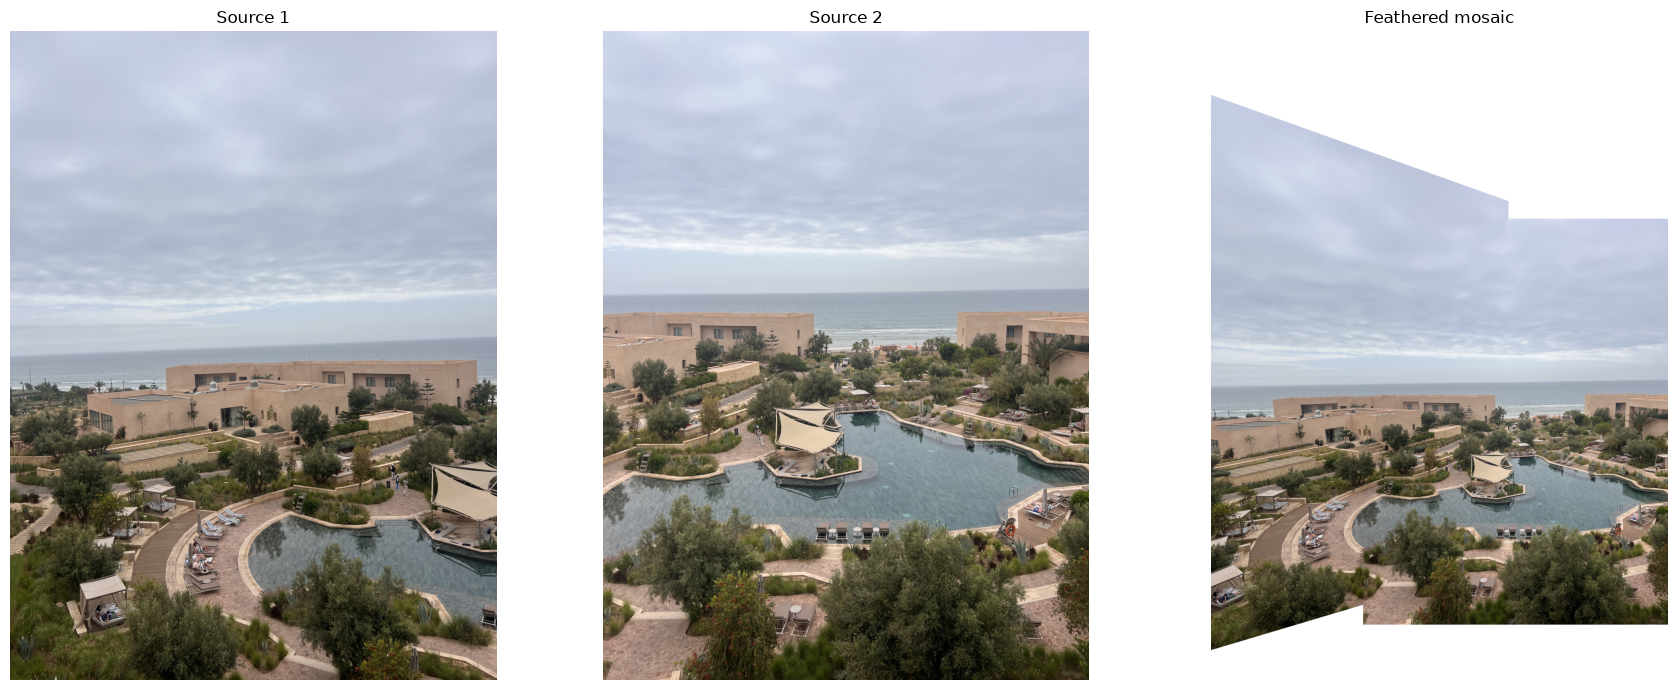

In [21]:
mosaic1 = show_mosaic(im1_half, im2_half, H_RANSAC)

In [22]:
def auto_H(name1, name2, t=0.7, return_points=False):
    """Full automatic pipeline for one pair. Returns (H for 0.5-scale images, inlier count, match count)."""
    _, g1 = load_image(name1)
    _, g2 = load_image(name2)
    a1, a2 = ANMS(g1), ANMS(g2)                               # (2, N) as (row, col)
    f1 = feature_extraction(g1, a1).reshape(a1.shape[1], -1)
    f2 = feature_extraction(g2, a2).reshape(a2.shape[1], -1)

    d = dist2(f1, f2)
    c2 = np.argsort(d, axis=1)[:, :2]
    r = np.arange(len(d))
    e1, e2 = d[r, c2[:, 0]], d[r, c2[:, 1]]
    er = np.sqrt(np.maximum(e1, 0)) / np.sqrt(np.maximum(e2, 0) + 1e-12)
    keep = er < t

    p1 = a1.T[keep][:, ::-1]                                  # (row, col) -> (x, y)
    p2 = a2.T[c2[keep, 0]][:, ::-1]
    H, inl = RANSAC(p1, p2, scale=2)
    if return_points:
        return H, inl, p1, p2
    return H, inl.sum(), len(inl)

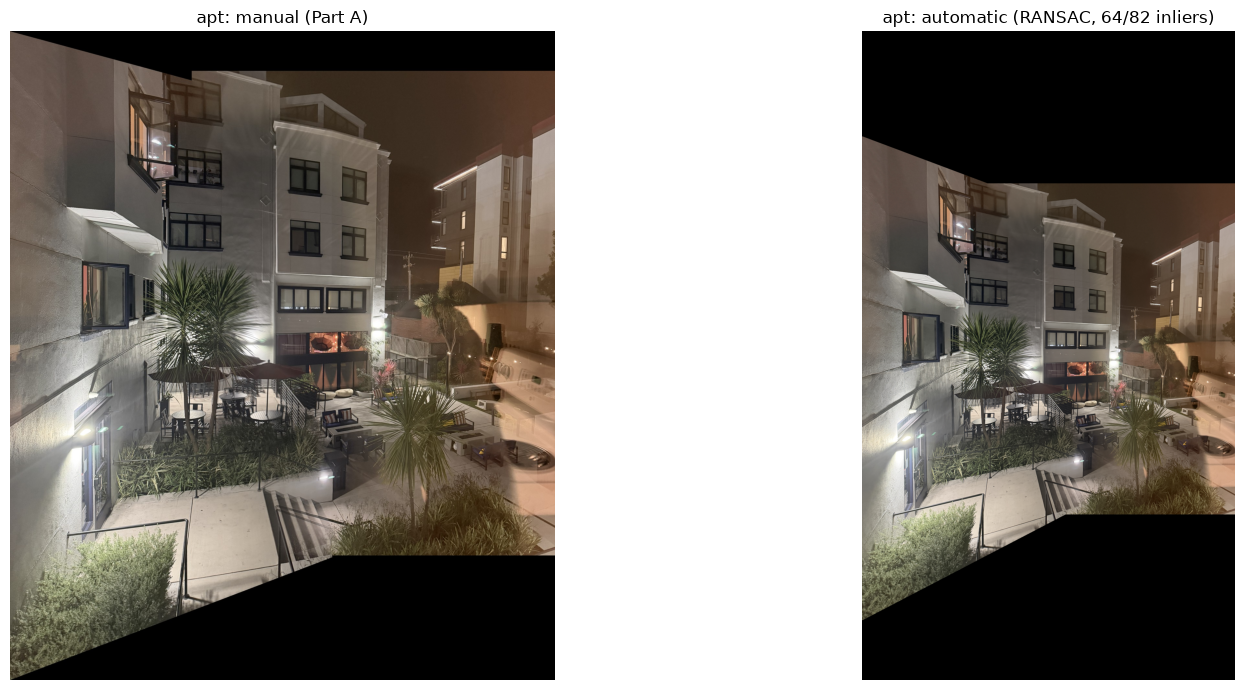

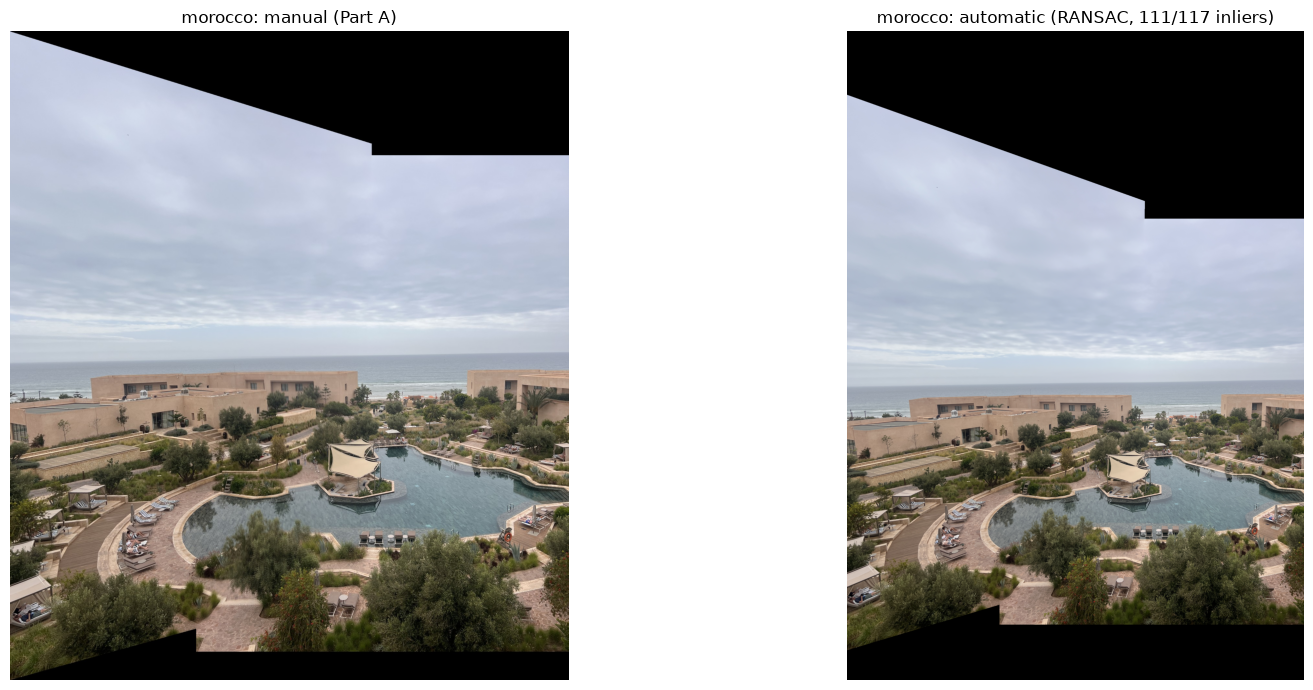

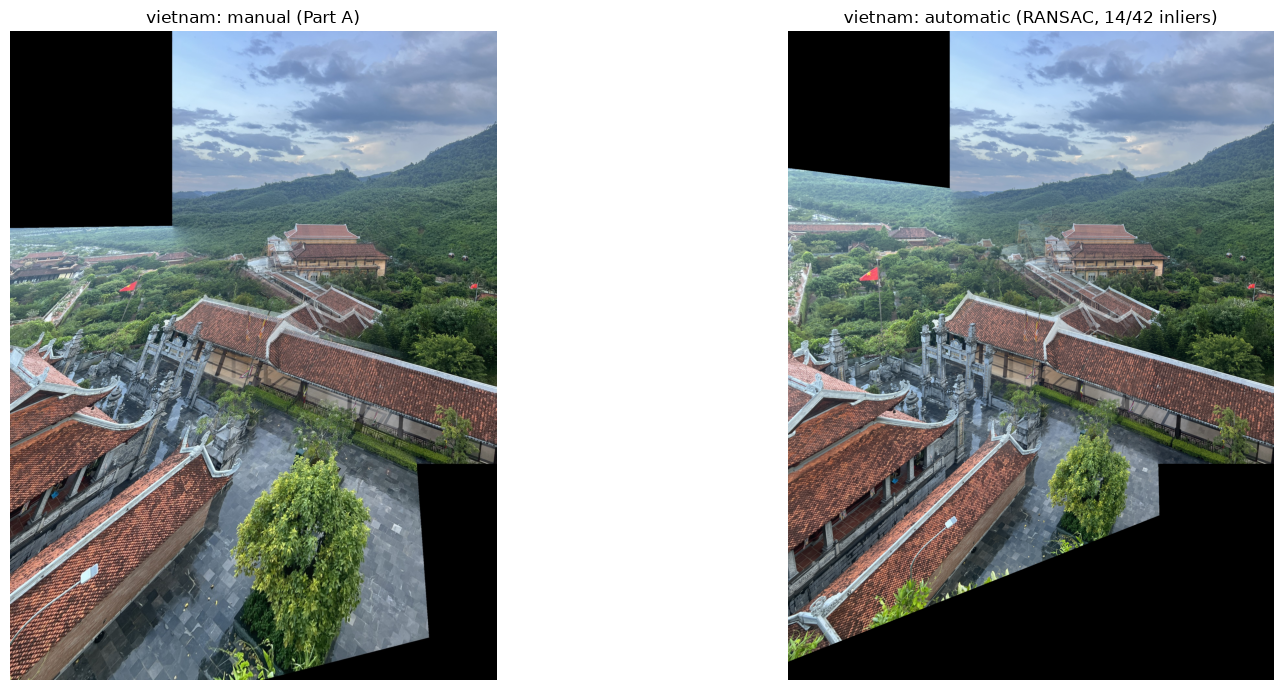

In [24]:
import os

PAIRS = [("apt", "apt1.jpg", "apt2.jpg"),
         ("morocco", "morocco1.jpg", "morocco2.jpg"),
         ("vietnam", "vietnam1.jpg", "vietnam2.jpg")]
A4_DIR = os.path.join("..", "proj4a", "results", "a4")
os.makedirs("results/b4", exist_ok=True)

for name, f1, f2 in PAIRS:
    manual = skio.imread(os.path.join(A4_DIR, f"{name}_mosaic.jpg"))
    auto_path = f"results/b4/{name}_auto_mosaic.jpg"

    if os.path.exists(auto_path):           
        auto = skio.imread(auto_path)
        n_in = n_match = None
    else:
        H, n_in, n_match = auto_H(f1, f2)
        im1_half, _ = load_image(f1, scale=0.5)
        im2_half, _ = load_image(f2, scale=0.5)
        mosaic, mask = make_mosaic(im1_half, im2_half, H)
        auto = np.clip(mosaic, 0, 1) * mask[..., None]
        plt.imsave(auto_path, auto)

    title = f"{name}: automatic (RANSAC" + (f", {n_in}/{n_match} inliers)" if n_in is not None else ")")
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    axes[0].imshow(manual); axes[0].set_title(f"{name}: manual (Part A)")
    axes[1].imshow(auto);   axes[1].set_title(title)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"results/b4/{name}_compare.png", dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
# B.4: inliers per pair (table on the website) and a plot of the inlier matches
import json

inlier_counts = {}
for name, f1, f2 in PAIRS:
    H, inl, p1, p2 = auto_H(f1, f2, return_points=True)
    inlier_counts[name] = {"matches": int(len(inl)), "inliers": int(inl.sum())}
    print(f"{name:8s} {inl.sum():4d} / {len(inl):4d} inliers")

    im1, _ = load_image(f1)
    im2, _ = load_image(f2)
    # (x, y) -> (row, col) for show_matches
    show_matches(im1, im2, p1[inl][:, ::-1].T, p2[inl][:, ::-1].T,
                 title=f"{name}: RANSAC inliers {inl.sum()} / {len(inl)}",
                 save_path=f"results/b4/{name}_inliers.png")

with open("results/b4/inliers.json", "w") as fp:
    json.dump(inlier_counts, fp, indent=1)
